# Can one textbook model explain UK interest rates since 1997?

Fits the Vasicek short-rate model to the Bank of England's month-end 1-year gilt spot rate (June 1997 to August 2026), refits it by policy regime, simulates rate paths and prices zero-coupon bonds. It then stress-tests the model against real UK events (the 2008 crash, the 2022 mini-budget) and values a 30-year pension liability on the model's curve and on the market's. Findings and limitations are in `README.md`.

Run top to bottom. Random seeds are fixed, so every number reproduces.

## 1. Load the data

The short-rate proxy is the Bank of England's 1-year nominal gilt spot rate, month-end, from June 1997.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

curve = pd.read_csv("data/uk_gilt_spot_monthly.csv", index_col=0, parse_dates=True)
series = curve["1.0"]["1997-06":] / 100      # 1-year spot rate as a decimal (0.05 = 5%)
dates = series.index
r = series.values                            # plain numpy array from here on
dt = 1 / 12                                  # one month, in years

print(f"{len(r)} month-ends, {dates[0]:%b %Y} to {dates[-1]:%b %Y}")

351 month-ends, Jun 1997 to Aug 2026


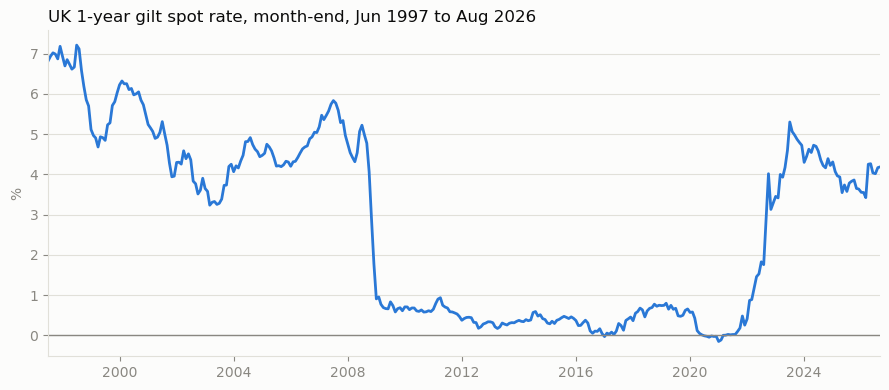

In [2]:
SURFACE, INK, MUTED, GRID, BLUE = "#fcfcfb", "#0b0b0b", "#898781", "#e1e0d9", "#2a78d6"

fig, ax = plt.subplots(figsize=(9, 4), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.plot(dates, r * 100, color=BLUE, linewidth=2)
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_xlim(dates[0], dates[-1])
ax.set_title(f"UK 1-year gilt spot rate, month-end, {dates[0]:%b %Y} to {dates[-1]:%b %Y}", loc="left", color=INK)
ax.set_ylabel("%", color=MUTED)
ax.grid(axis="y", color=GRID, linewidth=0.8)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color(GRID)
ax.tick_params(colors=MUTED)
fig.tight_layout()
fig.savefig("figures/uk_1y_rate.png", dpi=200)
plt.show()

## 2. Fit by least squares

Solving the SDE $dr_t = a(b - r_t)\,dt + \sigma\,dW_t$ exactly gives a monthly AR(1):

$$r_{k+1} = c + \varphi\, r_k + \varepsilon_k, \qquad \varphi = e^{-a\Delta}, \quad c = b(1-\varphi), \quad \varepsilon_k \sim N\!\left(0,\ \tfrac{\sigma^2}{2a}(1-\varphi^2)\right)$$

So regress next month's rate on this month's, then invert the coefficients.

In [3]:
# Regression data: x = this month's rate, y = next month's rate.
x = r[:-1]
y = r[1:]

assert len(x) == len(y) == len(r) - 1

In [4]:
# Design matrix: a column of ones (intercept c) and x (slope phi).
X = np.column_stack([np.ones(len(x)), x])

assert X.shape == (len(x), 2)

In [5]:
# Least squares via the normal equations (X^T X) beta = X^T y.
beta = np.linalg.solve(X.T @ X, X.T @ y)
c_hat, phi_hat = beta

print(f"c = {c_hat:.6f}, phi = {phi_hat:.4f}")

c = 0.000168, phi = 0.9911


In [6]:
# Residuals, residual variance s^2 (n - 2 degrees of freedom), covariance matrix s^2 (X^T X)^{-1}.
n = len(y)
resid = y - X @ beta
s2 = resid @ resid / (n - 2)
cov_beta = s2 * np.linalg.inv(X.T @ X)
se_c, se_phi = np.sqrt(np.diag(cov_beta))

# With an intercept, least squares forces the residuals to sum to zero.
assert abs(resid.sum()) < 1e-10
print(f"SE(c) = {se_c:.6f}, SE(phi) = {se_phi:.4f}")

SE(c) = 0.000187, SE(phi) = 0.0053


In [7]:
# 95% confidence interval for phi.
tq = stats.t.ppf(0.975, n - 2)       # t quantile with n - 2 degrees of freedom (about 1.97 here)
phi_lo = phi_hat - tq * se_phi
phi_hi = phi_hat + tq * se_phi

print(f"phi = {phi_hat:.4f}, 95% CI [{phi_lo:.4f}, {phi_hi:.4f}]")

phi = 0.9911, 95% CI [0.9808, 1.0014]


In [8]:
# Invert the AR(1) coefficients to the model's parameters.
a_hat = -np.log(phi_hat) / dt
b_hat = c_hat / (1 - phi_hat)
sigma_hat = np.sqrt(2 * a_hat * s2 / (1 - phi_hat**2))
half_life = np.log(2) / a_hat

print(f"a = {a_hat:.3f} per year, b = {b_hat:.2%}, sigma = {sigma_hat:.2%}, half-life = {half_life:.1f} years")

a = 0.107 per year, b = 1.89%, sigma = 0.78%, half-life = 6.5 years


In [9]:
# Half-life interval: the half-life is increasing in phi, so map the endpoints across.
# If the interval for phi reaches 1, the half-life has no finite upper bound.
hl_lo = dt * np.log(2) / -np.log(phi_lo)
hl_hi = dt * np.log(2) / -np.log(phi_hi) if phi_hi < 1 else np.inf

print(f"half-life = {half_life:.1f} years, 95% CI [{hl_lo:.1f}, {hl_hi:.1f}] years")

half-life = 6.5 years, 95% CI [3.0, inf] years


## 3. Check against a library

The hand-written least squares must match `statsmodels`.

In [10]:
import statsmodels.api as sm

check = sm.OLS(y, X).fit()
print("statsmodels:", check.params, check.bse)
print("yours:      ", beta, np.array([se_c, se_phi]))
assert np.allclose(check.params, beta) and np.allclose(check.bse, [se_c, se_phi])

statsmodels: [1.67966917e-04 9.91095562e-01] [0.0001868  0.00526005]
yours:       [1.67966917e-04 9.91095562e-01] [0.0001868  0.00526005]


## 4. One function, then refit by regime

In [11]:
def fit_vasicek(r, dt=1/12):
    """Fit Vasicek to short rates r (decimals, one every dt years) by least squares on the exact AR(1) form."""
    x, y = r[:-1], r[1:]
    X = np.column_stack([np.ones(len(x)), x])
    c_hat, phi_hat = np.linalg.solve(X.T @ X, X.T @ y)
    n = len(y)
    resid = y - X @ np.array([c_hat, phi_hat])
    s2 = resid @ resid / (n - 2)
    se_phi = np.sqrt(s2 * np.linalg.inv(X.T @ X)[1, 1])
    tq = stats.t.ppf(0.975, n - 2)
    phi_lo, phi_hi = phi_hat - tq * se_phi, phi_hat + tq * se_phi
    a_hat = -np.log(phi_hat) / dt
    b_hat = c_hat / (1 - phi_hat)
    sigma_hat = np.sqrt(2 * a_hat * s2 / (1 - phi_hat**2))
    half_life = np.log(2) / a_hat
    hl_lo = dt * np.log(2) / -np.log(phi_lo)
    hl_hi = dt * np.log(2) / -np.log(phi_hi) if phi_hi < 1 else np.inf

    return {"n": n, "phi": phi_hat, "phi_lo": phi_lo, "phi_hi": phi_hi,
            "a": a_hat, "b": b_hat, "sigma": sigma_hat,
            "half_life": half_life, "hl_lo": hl_lo, "hl_hi": hl_hi}

full = fit_vasicek(r)
assert np.isclose(full["phi"], phi_hat) and np.isclose(full["half_life"], half_life)

# Test the function on the first 10 years only, against statsmodels.
sub = r[:120]
chk = sm.OLS(sub[1:], sm.add_constant(sub[:-1])).fit()
p = chk.params[1]
a_chk = -np.log(p) / dt
test = fit_vasicek(sub)
assert test["n"] == 119
assert np.isclose(test["phi"], p)
assert np.isclose(test["phi_hi"], p + stats.t.ppf(0.975, 117) * chk.bse[1])
assert np.isclose(test["sigma"], np.sqrt(2 * a_chk * chk.scale / (1 - p**2)))
assert np.isclose(test["half_life"], np.log(2) / a_chk)
print("fit_vasicek passes")

fit_vasicek passes


Regime dates follow Bank of England decisions: operational independence (June 1997), the crisis cuts from October 2008 to March 2009 (left out as a transition), and the first rate rise (December 2021).
They were chosen after looking at the data, so the table describes how the estimates differ across eras. It is not a test for a structural break.

In [12]:
regimes = {
    "Jun 1997 - Aug 2008 (pre-crisis)":  ("1997-06", "2008-08"),
    "Mar 2009 - Nov 2021 (near-zero)":   ("2009-03", "2021-11"),
    "Dec 2021 - latest (hikes and after)": ("2021-12", None),
}

fits = {name: fit_vasicek(series[start:end].values) for name, (start, end) in regimes.items()}
fits["Full sample"] = full

table = pd.DataFrame(fits).T
table["n"] = table["n"].astype(int)
pct = lambda v: f"{v:.2%}"
yrs = lambda v: "inf" if np.isinf(v) else f"{v:.1f}"
print(table.to_string(formatters={"phi": "{:.4f}".format, "phi_lo": "{:.4f}".format, "phi_hi": "{:.4f}".format,
                                  "a": "{:.3f}".format, "b": pct, "sigma": pct,
                                  "half_life": yrs, "hl_lo": yrs, "hl_hi": yrs}))

                                       n    phi phi_lo phi_hi     a     b sigma half_life hl_lo hl_hi
Jun 1997 - Aug 2008 (pre-crisis)     134 0.9645 0.9283 1.0007 0.433 4.58% 0.73%       1.6   0.8   inf
Mar 2009 - Nov 2021 (near-zero)      152 0.9355 0.8800 0.9910 0.800 0.36% 0.31%       0.9   0.5   6.4
Dec 2021 - latest (hikes and after)   56 0.8793 0.8045 0.9540 1.544 4.25% 1.16%       0.4   0.3   1.2
Full sample                          350 0.9911 0.9808 1.0014 0.107 1.89% 0.78%       6.5   3.0   inf


## 5. Simulation

Exact simulation from the AR(1) form: 10,000 five-year monthly paths from the August 2026 rate, under the full-sample and post-2021 parameters.

In [13]:
# Exact simulation. Each month: r_next = b + phi * (r - b) + sd * Z, with Z ~ N(0, 1).
def simulate_vasicek(r0, a, b, sigma, years=5, dt=1/12, n_paths=10_000, seed=0):
    rng = np.random.default_rng(seed)                      # seeded, so results are reproducible
    n_steps = int(round(years / dt))
    phi = np.exp(-a * dt)
    sd = sigma * np.sqrt((1 - phi**2) / (2 * a))           # exact one-month noise standard deviation
    paths = np.empty((n_paths, n_steps + 1))
    paths[:, 0] = r0
    for k in range(n_steps):
        paths[:, k + 1] = b + phi * (paths[:, k] - b) + sd * rng.standard_normal(n_paths)
    return paths

# Theory: mean and variance of r_t given r_0.
def vasicek_mean(r0, a, b, t):
    return b + (r0 - b) * np.exp(-a * t)

def vasicek_var(a, sigma, t):
    return sigma**2 / (2 * a) * (1 - np.exp(-2 * a * t))

In [14]:
# Simulate 10,000 five-year paths from the latest rate, under two sets of fitted parameters.
r0 = r[-1]
scenarios = {
    "Full sample (1997-2026)": full,
    "Since Dec 2021": fits["Dec 2021 - latest (hikes and after)"],
}
sims = {name: simulate_vasicek(r0, p["a"], p["b"], p["sigma"]) for name, p in scenarios.items()}
first = sims["Full sample (1997-2026)"]
print(f"Start: {r0:.2%} ({dates[-1]:%b %Y}); {first.shape[0]:,} paths of {first.shape[1] - 1} months each")

Start: 4.18% (Aug 2026); 10,000 paths of 60 months each


In [15]:
# Check the simulation against the theory at the 5-year horizon.
# The simulated mean should be within about 3 Monte Carlo standard errors of the theoretical mean.
T = 5
rows = {}
for name, p in scenarios.items():
    end = sims[name][:, -1]
    m_th, sd_th = vasicek_mean(r0, p["a"], p["b"], T), np.sqrt(vasicek_var(p["a"], p["sigma"], T))
    mc_se = end.std() / np.sqrt(len(end))
    rows[name] = {"mean (sim)": end.mean(), "mean (theory)": m_th, "sd (sim)": end.std(), "sd (theory)": sd_th,
                  "gap in MC std errors": (end.mean() - m_th) / mc_se}
    assert abs(end.mean() - m_th) < 4 * mc_se and abs(end.std() / sd_th - 1) < 0.03
moments = pd.DataFrame(rows).T
print(moments.to_string(formatters={c: pct for c in moments.columns if "MC" not in c} | {"gap in MC std errors": "{:+.2f}".format}))

                        mean (sim) mean (theory) sd (sim) sd (theory) gap in MC std errors
Full sample (1997-2026)      3.25%         3.23%    1.35%       1.36%                +1.33
Since Dec 2021               4.26%         4.25%    0.66%       0.66%                +1.51


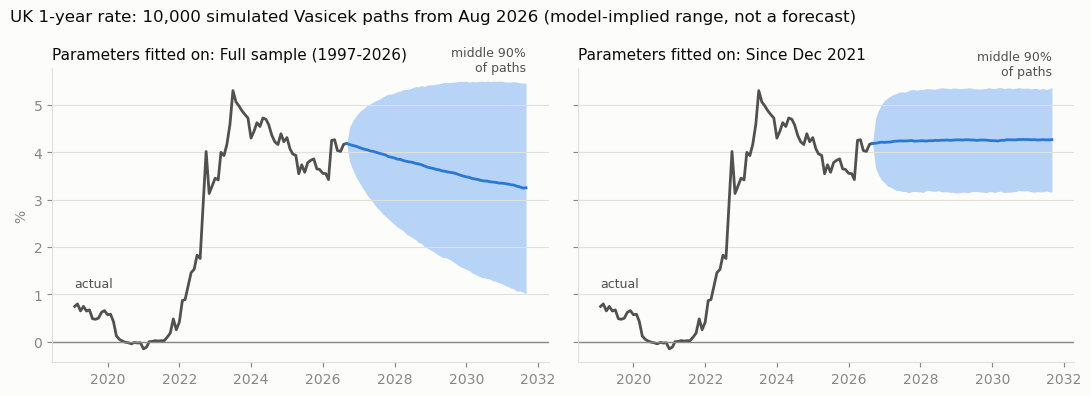

In [16]:
# Fan chart. Shaded band = middle 90% of simulated paths; line = median.
LIGHT_BLUE, SECONDARY = "#b7d3f6", "#52514e"
future = pd.date_range(dates[-1], periods=sims[list(sims)[0]].shape[1], freq="ME")
hist = series["2019-01":]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, facecolor=SURFACE)
for ax, (name, paths) in zip(axes, sims.items()):
    lo, med, hi = np.percentile(paths, [5, 50, 95], axis=0)
    ax.set_facecolor(SURFACE)
    ax.plot(hist.index, hist.values * 100, color=SECONDARY, linewidth=2)
    ax.fill_between(future, lo * 100, hi * 100, color=LIGHT_BLUE, linewidth=0)
    ax.plot(future, med * 100, color=BLUE, linewidth=2)
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.text(future[-1], hi[-1] * 100 + 0.2, "middle 90%\nof paths", ha="right", va="bottom", color=SECONDARY, fontsize=9)
    ax.text(hist.index[0], hist.values[0] * 100 + 0.4, "actual", color=SECONDARY, fontsize=9)
    ax.set_title(f"Parameters fitted on: {name}", loc="left", color=INK, fontsize=11)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED)
axes[0].set_ylabel("%", color=MUTED)
fig.suptitle(f"UK 1-year rate: 10,000 simulated Vasicek paths from {dates[-1]:%b %Y} (model-implied range, not a forecast)",
             x=0.01, ha="left", color=INK)
fig.tight_layout()
fig.savefig("figures/vasicek_fan_chart.png", dpi=200)
plt.show()

## 6. Negative rates: model against reality

In [17]:
# How likely does the model think negative rates are, and how often did they actually happen?
# Normal distribution, so P(r < 0) = Phi(-mean / sd). Long run: mean b, variance sigma^2 / (2a).
rows = {}
for name, p in scenarios.items():
    m5, sd5 = vasicek_mean(r0, p["a"], p["b"], T), np.sqrt(vasicek_var(p["a"], p["sigma"], T))
    sd_inf = p["sigma"] / np.sqrt(2 * p["a"])
    rows[name] = {"P(r<0) in 5 yrs, sim": (sims[name][:, -1] < 0).mean(),
                  "P(r<0) in 5 yrs, theory": stats.norm.cdf(-m5 / sd5),
                  "P(r<0) long run, theory": stats.norm.cdf(-p["b"] / sd_inf)}
neg = pd.DataFrame(rows).T
print(neg.to_string(formatters={c: "{:.2%}".format for c in neg.columns}))
print(f"\nActual: the 1-year rate was below zero in {(r < 0).sum()} of {len(r)} months ({(r < 0).mean():.1%}), "
      f"lowest {r.min():.2%} ({dates[r.argmin()]:%b %Y})")

                        P(r<0) in 5 yrs, sim P(r<0) in 5 yrs, theory P(r<0) long run, theory
Full sample (1997-2026)                0.82%                   0.88%                  13.04%
Since Dec 2021                         0.00%                   0.00%                   0.00%

Actual: the 1-year rate was below zero in 9 of 351 months (2.6%), lowest -0.15% (Dec 2020)


## 7. Zero-coupon bond: closed form vs Monte Carlo

Prices assume no risk premium (historical parameters used as if risk-neutral).

In [18]:
# Closed-form zero-coupon bond price (pays 1 at time T), assuming no risk premium.
# P = exp(-M + V/2), where M and V are the mean and variance of the integral of r from 0 to T (it is normal).
def vasicek_B(a, T):
    return (1 - np.exp(-a * T)) / a

def vasicek_bond_price(r0, a, b, sigma, T):
    B = vasicek_B(a, T)
    M = b * T + (r0 - b) * B
    V = sigma**2 / a**2 * (T - 2 * B + (1 - np.exp(-2 * a * T)) / (2 * a))
    return np.exp(-M + V / 2)

def bond_yield(price, T):
    return -np.log(price) / T                  # continuously compounded, same convention as the BoE curve

In [19]:
# Monte Carlo price = average over paths of exp(-integral of r), integral by the trapezium rule.
# Weekly steps so the trapezium error is tiny. Keeps only the current rate, so 100,000 paths fit in memory.
def mc_bond_price(r0, a, b, sigma, T, n_paths, dt=1/52, seed=1):
    rng = np.random.default_rng(seed)
    phi = np.exp(-a * dt)
    sd = sigma * np.sqrt((1 - phi**2) / (2 * a))
    rate = np.full(n_paths, r0)
    integral = np.zeros(n_paths)
    for _ in range(int(round(T / dt))):
        new = b + phi * (rate - b) + sd * rng.standard_normal(n_paths)
        integral += (rate + new) / 2 * dt
        rate = new
    discount = np.exp(-integral)
    return discount.mean(), discount.std() / np.sqrt(n_paths)      # price and its Monte Carlo standard error

In [20]:
# Does Monte Carlo converge to the formula? 5-year bond, full-sample parameters.
p = full
exact = vasicek_bond_price(r0, p["a"], p["b"], p["sigma"], 5)
rows = {}
for n_paths in [1_000, 10_000, 100_000]:
    price, se = mc_bond_price(r0, p["a"], p["b"], p["sigma"], 5, n_paths)
    rows[f"{n_paths:,} paths"] = {"MC price": price, "formula": exact, "error": price - exact,
                                  "MC std error": se, "error in std errors": (price - exact) / se}
conv = pd.DataFrame(rows).T
print(conv.to_string(formatters={"MC price": "{:.5f}".format, "formula": "{:.5f}".format, "error": "{:+.5f}".format,
                                 "MC std error": "{:.5f}".format, "error in std errors": "{:+.2f}".format}))
print("\nEach 10x more paths should shrink the std error by about sqrt(10) = 3.16x:",
      ", ".join(f"{conv['MC std error'].iloc[i] / conv['MC std error'].iloc[i + 1]:.2f}x" for i in range(2)))

              MC price formula    error MC std error error in std errors
1,000 paths    0.83488 0.83332 +0.00155      0.00108               +1.43
10,000 paths   0.83319 0.83332 -0.00013      0.00034               -0.39
100,000 paths  0.83316 0.83332 -0.00016      0.00011               -1.48

Each 10x more paths should shrink the std error by about sqrt(10) = 3.16x: 3.15x, 3.16x


## 8. Model yield curve vs the actual gilt curve

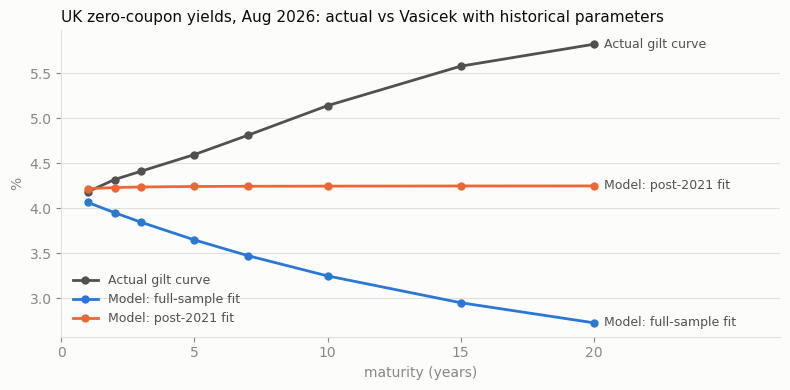

    actual model, Full sample (1997-2026) model, Since Dec 2021 gap, full-sample fit
1y   4.18%                          4.06%                 4.22%                0.12%
2y   4.32%                          3.95%                 4.23%                0.37%
3y   4.41%                          3.84%                 4.24%                0.57%
5y   4.60%                          3.65%                 4.24%                0.95%
7y   4.81%                          3.47%                 4.24%                1.34%
10y  5.14%                          3.25%                 4.25%                1.89%
15y  5.58%                          2.95%                 4.25%                2.63%
20y  5.82%                          2.72%                 4.25%                3.10%


In [21]:
# Model yield curve vs the actual gilt curve on the same day.
# The model uses historical parameters and assumes no risk premium, so a gap is expected: that is the finding.
ORANGE = "#eb6834"
mats = np.array([1, 2, 3, 5, 7, 10, 15, 20])
actual = curve.loc[dates[-1], [f"{m:.1f}" for m in mats]].values / 100
model = {name: bond_yield(vasicek_bond_price(r0, p["a"], p["b"], p["sigma"], mats), mats) for name, p in scenarios.items()}

fig, ax = plt.subplots(figsize=(8, 4), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
lines = [("Actual gilt curve", actual, SECONDARY), ("Model: full-sample fit", model["Full sample (1997-2026)"], BLUE),
         ("Model: post-2021 fit", model["Since Dec 2021"], ORANGE)]
for label, ys, colour in lines:
    ax.plot(mats, ys * 100, color=colour, linewidth=2, marker="o", markersize=5, label=label)
    ax.text(mats[-1] + 0.4, ys[-1] * 100, label, color=SECONDARY, fontsize=9, va="center")
ax.set_xlim(0, 27)
ax.set_xticks([0, 5, 10, 15, 20])
ax.set_title(f"UK zero-coupon yields, {dates[-1]:%b %Y}: actual vs Vasicek with historical parameters", loc="left", color=INK, fontsize=11)
ax.set_xlabel("maturity (years)", color=MUTED)
ax.set_ylabel("%", color=MUTED)
ax.legend(frameon=False, loc="lower left", labelcolor=SECONDARY, fontsize=9)
ax.grid(axis="y", color=GRID, linewidth=0.8)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color(GRID)
ax.tick_params(colors=MUTED)
fig.tight_layout()
fig.savefig("figures/yield_curve_vs_model.png", dpi=200)
plt.show()

yc = pd.DataFrame({"actual": actual} | {f"model, {k}": v for k, v in model.items()}, index=[f"{m}y" for m in mats])
yc["gap, full-sample fit"] = yc["actual"] - yc["model, Full sample (1997-2026)"]
print(yc.to_string(formatters={c: "{:.2%}".format for c in yc.columns}))

## 9. Where the normal shocks break: 2008 and the 2022 mini-budget

If the model is right, the standardised residuals behave like $N(0,1)$ draws, so about $350 \times 2(1-\Phi(3)) \approx 0.9$ months should fall beyond $\pm 3$.
These are residuals from the full-sample fit, so some of the fat tail is regime change showing up as shocks. Event labels are hand-written; March 2026 is left unlabelled.

In [22]:
# Are the monthly shocks really normal? Standardised residuals from the full-sample fit.
x, y = r[:-1], r[1:]
X = np.column_stack([np.ones(len(x)), x])
resid = y - X @ np.linalg.solve(X.T @ X, X.T @ y)
z = resid / resid.std(ddof=2)
shock_dates = dates[1:]                      # shock k moves the rate from month k to month k+1

n_extreme = int((np.abs(z) > 3).sum())
expected = len(z) * 2 * stats.norm.sf(3)
print(f"Excess kurtosis: {stats.kurtosis(resid):.1f} (0 for a normal distribution)")
print(f"Months beyond 3 standard deviations: {n_extreme}, against {expected:.1f} expected if shocks were normal")
print(f"Jarque-Bera test of normality: p-value {stats.jarque_bera(resid).pvalue:.0e}\n")

events = {
    "2008-09": "Lehman Brothers collapses (15 Sep)",
    "2008-10": "Post-Lehman emergency rate cuts begin",
    "2008-11": "Bank Rate cut by 1.5 points",
    "2008-12": "Bank Rate cut by 1 point",
    "2022-08": "0.5-point hike; BoE forecasts 13% inflation",
    "2022-09": "Mini-budget (23 Sep)",
    "2022-10": "BoE gilt intervention; mini-budget reversed",
    "2023-06": "Inflation surprise; 0.5-point hike to 5%",
}
extreme = pd.DataFrame({"shock (sd)": z, "move (points)": (y - x) * 100}, index=shock_dates)
extreme = extreme[np.abs(extreme["shock (sd)"]) > 3].sort_values("shock (sd)", key=np.abs, ascending=False)
extreme["event"] = [events.get(f"{d:%Y-%m}", "") for d in extreme.index]
extreme.index = extreme.index.strftime("%b %Y")
print(extreme.to_string(formatters={"shock (sd)": "{:+.1f}".format, "move (points)": "{:+.2f}".format}))

Excess kurtosis: 8.5 (0 for a normal distribution)
Months beyond 3 standard deviations: 9, against 0.9 expected if shocks were normal
Jarque-Bera test of normality: p-value 3e-229

         shock (sd) move (points)                                        event
date                                                                          
Oct 2008       -5.3         -1.20        Post-Lehman emergency rate cuts begin
Aug 2022       +5.2         +1.15  0.5-point hike; BoE forecasts 13% inflation
Sep 2022       +5.0         +1.10                         Mini-budget (23 Sep)
Nov 2008       -4.8         -1.09                  Bank Rate cut by 1.5 points
Dec 2008       -3.9         -0.87                     Bank Rate cut by 1 point
Oct 2022       -3.9         -0.89  BoE gilt intervention; mini-budget reversed
Mar 2026       +3.8         +0.83                                             
Jun 2023       +3.3         +0.71     Inflation surprise; 0.5-point hike to 5%
Sep 2008       -3.1         -

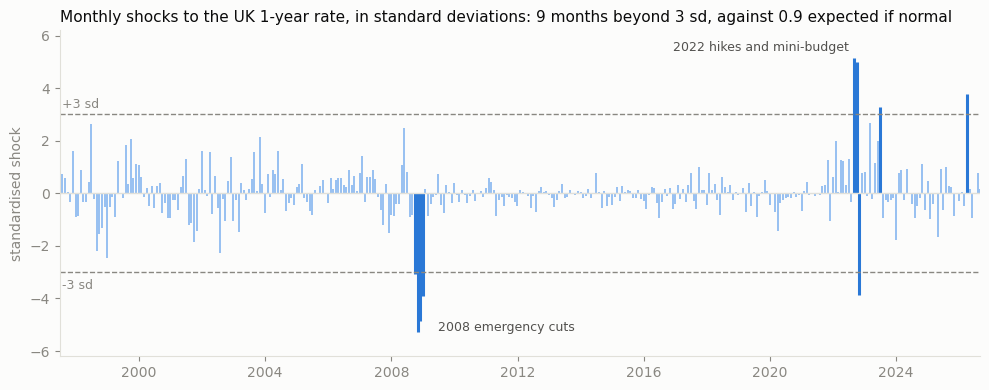

In [23]:
# Chart: every monthly shock in standard deviations. A normal model would almost never cross the dashed lines.
fig, ax = plt.subplots(figsize=(10, 4), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
big = np.abs(z) > 3
ax.vlines(shock_dates[~big], 0, z[~big], color="#86b6ef", linewidth=1.2)
ax.vlines(shock_dates[big], 0, z[big], color=BLUE, linewidth=2.2)
for level in (3, -3):
    ax.axhline(level, color=MUTED, linewidth=1, linestyle="--")
ax.axhline(0, color=GRID, linewidth=1)
ax.text(dates[1], 3.25, "+3 sd", color=MUTED, fontsize=9)
ax.text(dates[1], -3.65, "-3 sd", color=MUTED, fontsize=9)
ax.text(pd.Timestamp("2009-06-30"), -5.1, "2008 emergency cuts", color=SECONDARY, fontsize=9, va="center")
ax.text(pd.Timestamp("2022-06-30"), 5.55, "2022 hikes and mini-budget", color=SECONDARY, fontsize=9, ha="right", va="center")
ax.set_xlim(dates[0], dates[-1])
ax.set_ylim(-6.2, 6.2)
ax.set_title(f"Monthly shocks to the UK 1-year rate, in standard deviations: {n_extreme} months beyond 3 sd, "
             f"against {expected:.1f} expected if normal", loc="left", color=INK, fontsize=11)
ax.set_ylabel("standardised shock", color=MUTED)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color(GRID)
ax.tick_params(colors=MUTED)
fig.tight_layout()
fig.savefig("figures/shocks_vs_normal.png", dpi=200)
plt.show()

## 10. A 30-year pension liability: model curve vs market curve

Present value of 1 a year for 30 years, $\sum_{t=1}^{30} P(0,t)$, on the August 2026 gilt curve and on each model curve.

In [24]:
# A pension liability: pay 1 a year for 30 years. Value it on the market gilt curve and on each model curve.
years = np.arange(1, 31)
market_df = np.exp(-curve.loc[dates[-1], [f"{t:.1f}" for t in years]].values / 100 * years)   # market discount factors
pv = {"Market gilt curve": market_df.sum()}
for name, p in scenarios.items():
    pv[f"Model: {name}"] = vasicek_bond_price(r0, p["a"], p["b"], p["sigma"], years).sum()
liab = pd.DataFrame({"present value": pv})
liab["vs market"] = liab["present value"] / pv["Market gilt curve"] - 1
print(liab.to_string(formatters={"present value": "{:.2f}".format, "vs market": "{:+.1%}".format}))
fits_gap = pv["Model: Full sample (1997-2026)"] / pv["Model: Since Dec 2021"] - 1
print(f"\nChoice of estimation window alone changes the model's liability value by {fits_gap:.1%}")

                               present value vs market
Market gilt curve                      14.27     +0.0%
Model: Full sample (1997-2026)         19.92    +39.5%
Model: Since Dec 2021                  16.60    +16.3%

Choice of estimation window alone changes the model's liability value by 19.9%
